# Running an A/B test properly: plan, check, analyze, decide

**The setup.** An e-commerce team wants to test a redesigned checkout. Today 3.2% of visitors who reach the cart complete a purchase. The team would ship the new design if it lifts conversion by 8% or more.

This notebook walks through the whole experiment with `abtk`, on simulated data where the true effect is known (+9% on conversion), including the two mistakes that most often invalidate real tests: a broken traffic split and peeking at results.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import abtk

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
BLUE, ORANGE, GREY = "#3B5BDB", "#E8590C", "#868E96"

## 1. Plan before you start

Three numbers decide the sample size: the baseline rate, the smallest lift worth detecting (MDE), and how sure we want to be (alpha = 5% false positives, power = 80%).

In [2]:
baseline, mde, daily_users = 0.032, 0.08, 12_000
n, _ = abtk.sample_size_proportions(baseline, mde)
days = abtk.test_duration_days(2 * n, daily_users)
print(f"{n:,} users per group, {2 * n:,} in total")
print(f"At {daily_users:,} eligible users a day: run for {days} days (rounded to full weeks)")

77,062 users per group, 154,124 in total
At 12,000 eligible users a day: run for 14 days (rounded to full weeks)


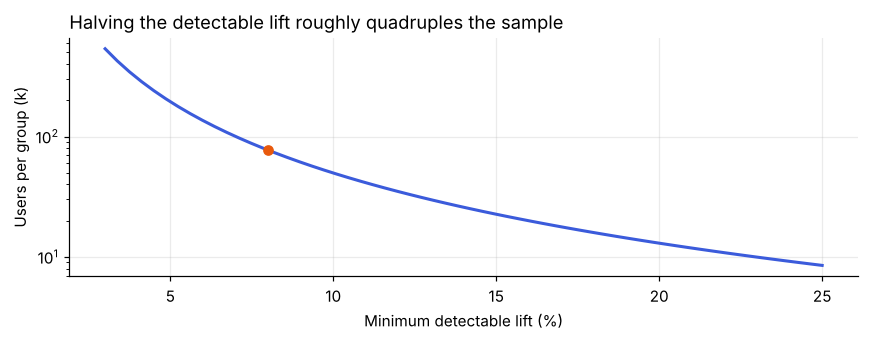

In [3]:
lifts = np.linspace(0.03, 0.25, 60)
sizes = [abtk.sample_size_proportions(baseline, m)[0] for m in lifts]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(lifts * 100, np.array(sizes) / 1000, color=BLUE, lw=2)
ax.scatter([mde * 100], [n / 1000], color=ORANGE, zorder=3)
ax.set_yscale("log")
ax.set_xlabel("Minimum detectable lift (%)")
ax.set_ylabel("Users per group (k)")
ax.set_title("Halving the detectable lift roughly quadruples the sample", loc="left")
fig.tight_layout()

The curve is why the MDE has to be agreed with the business up front. "Let's see if there's any effect" means running forever.

The run is rounded to two full weeks so every weekday appears equally often in both arms.

## 2. Simulate the experiment

Each user has a pre-experiment revenue (their spend in the four weeks before the test), which is correlated with how likely they are to convert. The treatment lifts conversion by 9%.

In [4]:
rng = np.random.default_rng(42)
n_c, n_t = n, n + 180
true_lift = 0.09
pre_revenue = rng.gamma(1.5, 30, n_c + n_t)
p_user = np.clip(baseline * (pre_revenue / pre_revenue.mean()) ** 0.5, 0, 1)
treat = np.r_[np.zeros(n_c, bool), np.ones(n_t, bool)]
converted = rng.random(n_c + n_t) < p_user * np.where(treat, 1 + true_lift, 1)
revenue = converted * rng.gamma(2.0, 35, n_c + n_t) + 0.15 * pre_revenue
users = pd.DataFrame({"group": np.where(treat, "treatment", "control"), "converted": converted,
                      "revenue": revenue, "pre_revenue": pre_revenue})
users.groupby("group").agg(users=("converted", "size"), conversion=("converted", "mean"), revenue_per_user=("revenue", "mean")).round(4)

,users,conversion,revenue_per_user
group,,,
control,77062,0.0297,8.7775
treatment,77242,0.0328,9.0977


## 3. Check the split before looking at results

A 50/50 test should end up close to 50/50. A sample ratio mismatch (SRM) means something in assignment or tracking is broken (bots, a redirect dropping users, a cache serving one variant), and the result can't be trusted however good it looks.

In [5]:
ok = abtk.srm_check(n_c, n_t)
broken = abtk.srm_check(n_c, int(n_t * 0.97))
print(f"This test:          {n_c:,} vs {n_t:,} -> p = {ok['p_value']:.3f}, mismatch: {ok['mismatch']}")
print(f"With 3% users lost: {n_c:,} vs {int(n_t * 0.97):,} -> p = {broken['p_value']:.2e}, mismatch: {broken['mismatch']}")

This test:          77,062 vs 77,242 -> p = 0.647, mismatch: False
With 3% users lost: 77,062 vs 74,924 -> p = 4.16e-08, mismatch: True


A 3% loss in one arm is invisible on a dashboard but obvious to the test. Here the split is fine, so we go on.

## 4. Did conversion improve?

In [6]:
conv = abtk.proportions_test(converted[~treat].sum(), n_c, converted[treat].sum(), n_t)
print(conv)

control 0.02969 vs treatment 0.03283: lift +10.58% (95% CI +4.60% to +16.91%), p = 0.0004, significant


Significant, with a 95% interval for the lift of roughly +5% to +17%. The point estimate (+10.6%) sits close to the true +9%.

## 5. Revenue per user, and how CUPED helps

Revenue per user is noisier than conversion: most users spend nothing, a few spend a lot. CUPED subtracts the part of each user's revenue that was predictable from before the test, which leaves the treatment effect intact but removes noise.

In [7]:
raw = abtk.means_test(revenue[~treat], revenue[treat])
adjusted, reduction = abtk.cuped(revenue, pre_revenue)
cup = abtk.means_test(adjusted[~treat], adjusted[treat])
pd.DataFrame({
    "lift": [raw.rel_lift, cup.rel_lift],
    "ci_low": [raw.ci_rel[0], cup.ci_rel[0]],
    "ci_high": [raw.ci_rel[1], cup.ci_rel[1]],
    "ci_width": [raw.ci_rel[1] - raw.ci_rel[0], cup.ci_rel[1] - cup.ci_rel[0]],
    "p_value": [raw.p_value, cup.p_value],
}, index=["raw", "CUPED"]).round(4)

,lift,ci_low,ci_high,ci_width,p_value
raw,0.0365,0.0179,0.0554,0.0375,0.0001
CUPED,0.0373,0.0202,0.0546,0.0344,0.0000


In [8]:
print(f"CUPED removed {reduction:.0%} of the variance in revenue per user.")
print(f"Equivalent to running the raw test with about {1 / (1 - reduction):.2f}x the users.")

CUPED removed 16% of the variance in revenue per user.
Equivalent to running the raw test with about 1.19x the users.


The same data, a tighter interval. In practice, CUPED is how teams shorten tests without giving up power.

## 6. A Bayesian view for the decision

A p-value says how surprising the data would be with no effect. Decision makers usually want something else: how likely is it that B is better, and what do we risk by shipping it?

In [9]:
bayes = abtk.bayesian_proportions(converted[~treat].sum(), n_c, converted[treat].sum(), n_t)
pd.Series(bayes).round(6).to_frame("value")

,value
prob_treatment_better,0.999800
expected_lift,0.106157
expected_loss_treatment,0.000000
expected_loss_control,0.003139


The probability that the new checkout converts better is essentially 100%, and the expected loss from shipping it (the conversion we'd give up if it were actually worse) is effectively zero.

## 7. The mistake that breaks most tests: peeking

Suppose the team had checked results every few days and stopped at the first p < 0.05. Under **no effect at all**, how often would they "find" a winner?

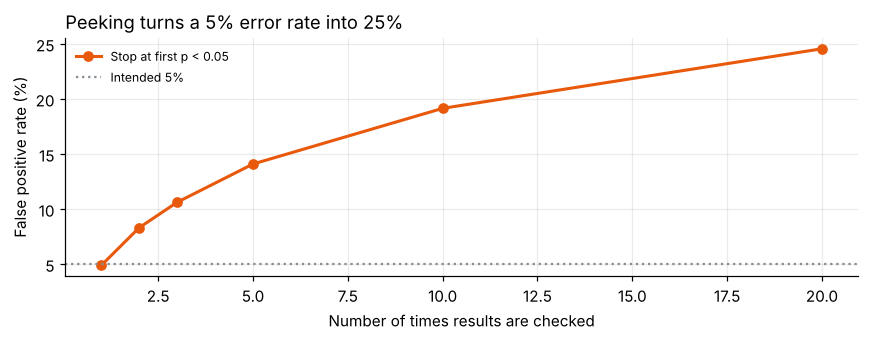

,1,2,3,5,10,20
false positive rate,0.049,0.083,0.106,0.141,0.192,0.246


In [10]:
looks = [1, 2, 3, 5, 10, 20]
naive = [abtk.false_positive_rate_with_peeking(k) for k in looks]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(looks, np.array(naive) * 100, color=ORANGE, lw=2, marker="o", label="Stop at first p < 0.05")
ax.axhline(5, color=GREY, ls=":", label="Intended 5%")
ax.set_xlabel("Number of times results are checked")
ax.set_ylabel("False positive rate (%)")
ax.set_title("Peeking turns a 5% error rate into 25%", loc="left")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
pd.Series(naive, index=looks, name="false positive rate").round(3).to_frame().T

Checking 20 times makes a "winner" appear in about one in four tests that do nothing.

### Peeking safely

If the business needs interim looks, plan them. O'Brien-Fleming boundaries make early looks very strict and the last one close to the usual 1.96, so the total error stays at 5%:

In [11]:
bounds = abtk.obrien_fleming_bounds(5)
safe = abtk.false_positive_rate_with_peeking(5, bounds=bounds)
plan = pd.DataFrame({"share of sample": [f"{k / 5:.0%}" for k in range(1, 6)], "z needed": bounds.round(2)}, index=[f"look {k}" for k in range(1, 6)])
print(f"False positive rate with these boundaries: {safe:.1%} (vs {abtk.false_positive_rate_with_peeking(5):.1%} with naive peeking)")
plan

False positive rate with these boundaries: 4.9% (vs 14.1% with naive peeking)


,share of sample,z needed
look 1,20%,4.57
look 2,40%,3.23
look 3,60%,2.64
look 4,80%,2.28
look 5,100%,2.04


A test with a huge effect can stop at look 2 or 3; everything else runs to the end at nearly the normal threshold.

## 8. Decision

| Check | Result |
|---|---|
| Sample size reached | Yes, planned 14 days |
| Traffic split (SRM) | OK |
| Conversion | +10.6%, 95% CI about +5% to +17% |
| Revenue per user (CUPED) | +3.7%, CI about +2% to +5% |
| P(treatment better) | ≈ 100% |

**Ship the new checkout.** The conversion lift clears the 8% target as a point estimate, though the lower end of the interval doesn't, so the honest summary is "a clear improvement, probably around the size we hoped for". A follow-up holdout after launch would confirm the effect holds.